In [1]:
import pandas as pd

df = pd.read_csv('customer-dataset.csv')
df

,Unnamed: 0,flags,instruction,category,intent,response
0,0,B,question about cancelling order {{Order Number}},ORDER,cancel_order,I've understood you have a question regarding ...
1,1,BQZ,i have a question about cancelling oorder {{Or...,ORDER,cancel_order,I've been informed that you have a question ab...
2,2,BLQZ,i need help cancelling puchase {{Order Number}},ORDER,cancel_order,I can sense that you're seeking assistance wit...
3,3,BL,I need to cancel purchase {{Order Number}},ORDER,cancel_order,I understood that you need assistance with can...
4,4,BCELN,"I cannot afford this order, cancel purchase {{...",ORDER,cancel_order,I'm sensitive to the fact that you're facing f...
...,...,...,...,...,...,...
26867,26867,BL,I am waiting for a rebate of {{Refund Amount}}...,REFUND,track_refund,Thank you for sharing your situation regarding...
26868,26868,BIL,how to see if there is anything wrong with my ...,REFUND,track_refund,Ensuring the accuracy of your restitution is o...
26869,26869,BLQZ,I'm waiting for a reimbjrsement of {{Currency ...,REFUND,track_refund,"Firstly, I genuinely understand the importance..."
26870,26870,BL,I don't know what to do to see my reimbursemen...,REFUND,track_refund,I've understood you're unsure about how to che...


In [2]:
categories_selected = ['ACCOUNT', 'ORDER', 'PAYMENT']
intents_selected = ['create_account', 'delete_account', 'edit_account',
                    'cancel_order', 'change_order', 'place_order',
                    'check_payment_methods', 'payment_issue']
ds_filtered = df[
    df['category'].isin(categories_selected) &
    df['intent'].isin(intents_selected)
]

ds_filtered = ds_filtered.rename(columns={"Unnamed: 0": "id"})
sampled = ds_filtered.groupby('intent', group_keys=False).sample(n=6, random_state=42)
train_df = sampled.groupby('intent', group_keys=False).head(3)
test_df = sampled.drop(train_df.index)
# train_df = train_df.reset_index(drop=True)
# test_df = test_df.reset_index(drop=True)
train_df

,id,flags,instruction,category,intent,response
453,453,BELN,I cannot afford purchase {{Order Number}},ORDER,cancel_order,I understand the financial constraints you are...
792,792,BCELV,"I have bought some item, I have to cancel orde...",ORDER,cancel_order,I recognize that you've recently made a purcha...
209,209,BCELN,"I do not want this item, cancel order {{Order ...",ORDER,cancel_order,I've observed that you no longer want the item...
1164,1164,BKL,modify order {{Order Number}},ORDER,change_order,Thank you for bringing up the request to modif...
1007,1007,BIL,can you help me correcting purchase {{Order Nu...,ORDER,change_order,I comprehend that you need assistance in corre...
1064,1064,BLQ,want help to update purchase {{Order Number}},ORDER,change_order,I've grasped that you need assistance with upd...
4944,4944,BL,see the available payment options,PAYMENT,check_payment_methods,Thank you for your interest in exploring our a...
5242,5242,BCL,"I have to list the payment modalities, help me",PAYMENT,check_payment_methods,For sure! I'd be delighted to assist you in li...
5256,5256,BLQZ,help me to check ur avialable payment options,PAYMENT,check_payment_methods,Positively! I'm here to assist you in checking...
10007,10007,BKLZ,opneing new {{Account Category}} account for d...,ACCOUNT,create_account,Thank you for choosing us to open a new {{Acco...


In [3]:
test_df

,id,flags,instruction,category,intent,response
309,309,BL,I need assistance with canceling purchase {{Or...,ORDER,cancel_order,I'm attuned to the idea that you require assis...
739,739,BILQZ,were can i cancel purchase {{Order Number}},ORDER,cancel_order,"I realized, you're looking for the information..."
578,578,BQ,want assistance to cancel order {{Order Number}},ORDER,cancel_order,"I've understood, you're seeking assistance wit..."
1562,1562,BCLZ,I have got to swap something of order {{Order ...,ORDER,change_order,We understand that you need assistance with sw...
1527,1527,BL,I want assistance changing a product of order ...,ORDER,change_order,Thank you for reaching out! I completely under...
1854,1854,BL,I need help to modify order {{Order Number}},ORDER,change_order,We're here to help! I take note that you need ...
5252,5252,BILQ,where can i list ur accepted payment methods,PAYMENT,check_payment_methods,Absolutely! I'd be delighted to assist you in ...
5541,5541,BCILZ,"I have got to see the payment opitons, how to ...",PAYMENT,check_payment_methods,I'll take care of it! I'm here to guide you. T...
5381,5381,BQZ,i try to check whatr payment methods uaccept,PAYMENT,check_payment_methods,I appreciate your interest in our payment meth...
10776,10776,BK,creating {{Account Type}} account,ACCOUNT,create_account,That's fantastic to hear that you're intereste...


In [ ]:
from harness_agent.harness import AgentHarness

from llm import get_llm
# model = get_llm("qwen/qwen3.8-27b")
model = get_llm("openai/gpt-oss-120b")
harness = AgentHarness(model = model, training_dataset=train_df, training_mode=True)
# response = harness.invoke("see the available payment options")
response = harness.invoke("help me to check ur avialable payment options")

response

before_agent 1 messages
before_agent 1 messages
request_supervisor: help me to check ur avialable payment options, refeerence: Example response: Positively! I'm here to assist you in checking the available payment options. To provide you with the most up-to-date information, could you please specify the country or region you are in? This will help me give you accurate and relevant details about the payment methods we offer in your area. Thank you!
{'messages': [HumanMessage(content='help me to check ur avialable payment options', additional_kwargs={}, response_metadata={}, id='87ce3138-9b86-4ba1-b00a-47f0db15f2d3'), AIMessage(content='', additional_kwargs={'tool_calls': [{'id': 'cf55yxyvd', 'function': {'arguments': '{"user_query":"help me to check ur avialable payment options"}', 'name': 'request_supervisor'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 36, 'prompt_tokens': 968, 'total_tokens': 1004, 'completion_time': 0.113599458, 'completion_tokens

BadRequestError: Error code: 400 - {'error': {'message': "tool call validation failed: attempted to call tool 'set_fact' which was not in request.tools", 'type': 'invalid_request_error', 'code': 'tool_use_failed', 'failed_generation': '<tool_call>\n<function=set_fact>\n<parameter=fact>\nThe user asked to check available payment options.\n</parameter>\n</function>\n</tool_call>'}}

In [4]:
# How to iterate
# for index, row in train_df.iterrows():
#     print(row.id,row['category'], row['intent'], row['instruction'])

#How to locate anaswer from query
response = train_df.loc[train_df["id"] == 453, "response"].iloc[0]
print(response)
# row.loc[0]    

I understand the financial constraints you are facing and the need to cancel purchase {{Order Number}}. Our goal is to assist you in the best way possible. To proceed with the cancellation, please follow these steps:

1. Sign in to Your Account: Access our {{Online Company Portal Info}} by signing in with your credentials.

2. Navigate to Your Orders: Once you are signed in, locate the '{{Online Order Interaction}}' or '{{Online Order Interaction}}' section.

3. Find the Relevant Purchase: Look for the purchase associated with the order number {{Order Number}} and click on it for more details.

4. Initiate Cancellation: You will see an option labeled '{{Online Order Interaction}}.' Please select this option to begin the cancellation process.

5. Complete the Cancellation: Follow any further instructions or prompts to complete the cancellation successfully.

If you encounter any issues or have any questions during the process, please don't hesitate to contact our dedicated customer supp

In [5]:
from llm import get_llm

# llm = get_llm("deepseek")
llm = get_llm("qwen/qwen3.8-27b")
response = llm.invoke([
    {
        "role": "system",
        "content": "an ai agent bot"
    },
    {
        "role": "user",
        "content": "what is CoALA framework"
    }
]
)

response

AIMessage(content='The **CoALA** framework stands for **Cognitive Architectures for Language Agents**. It is a conceptual framework proposed by researchers (notably from Stanford University, including researchers like Shunyu Yao, Jeffrey Zhao, and others) to provide a unified, structured way to understand, design, and evaluate **LLM-based agents**.\n\n### Core Idea\nCoALA treats an LLM agent as a **cognitive system** with distinct components, analogous to how human cognition is modeled in cognitive science. It breaks down an agent into four main modules:\n\n1. **Memory**\n2. **Action Space**\n3. **Decision-Making Module**\n4. **Perception Module**\n\nThis framework helps researchers and developers think systematically about how agents process information, make decisions, and interact with their environment.\n\n---\n\n### The Four Components of CoALA\n\n#### 1. Memory\nMemory is divided into two types:\n- **Short-term Memory (STM):**\n  - Typically implemented as the **context window** 

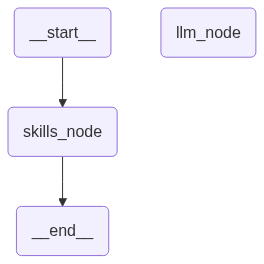

In [ ]:
import string
from typing import Annotated
from skills_manager import SkillsManager
from pydantic import BaseModel, Field
from langgraph.graph import END, START, MessagesState, StateGraph, add_messages
from langchain_core.messages import (
    AIMessage,
    AnyMessage,
    HumanMessage,
    SystemMessage,
)

class CustomState(BaseModel):
    messages:Annotated[list[AnyMessage], add_messages]= Field(default_factory=list, description= "Messages history")
    query: str = Field(default="",description = "query from user")

def llm_node(state: CustomState)-> dict:
    messages = state.messages
    system_prompt = "you AI tool!"
    
    if(not messages):
        messages.append(SystemMessage(system_prompt))

    text = ""

    while(text != "exit"):   
        text  = input("enter message")
        messages.append(HumanMessage(text))

        llm = get_llm("qwen/qwen3.8-27b")
        response = llm.invoke(messages)
        print(response)

        messages.append(response)

    return  {
        "messages" : messages
    }


from langchain.tools import tool

@tool
def request_supervisor(user_query: str) -> str:
    """Request an example of response to the user query
    Args:
        user_query (str): The user query
    """     
    print(f"request_supervisor: {user_query}")
    response = train_df.loc[train_df["instruction"] == user_query, "response"].iloc[0]
    return response


#TODO: Should this be implemented as small react?
def skills_node(state: CustomState)->dict:
    sm = SkillsManager()
    any_skill, skill_prompt = sm.generate_system_prompt()

    # if not any_skill:
    #     return {
    #         "relevant_skill": None
    #     }

    sm = SkillsManager()   

    #add tools for load skills
    #Addjson response
    tools = [sm.load_skill, request_supervisor]
    llm = get_llm("qwen/qwen3.8-27b").bind_tools(tools)
    # print(llm.kwargs["tools"])  # full schema that goes to the provider
    messages = []    
    messages.append(SystemMessage(skill_prompt))
    messages.append(HumanMessage(state.query))
    response = llm.invoke(messages)
    print (response)
    return {
        "sth":""
    }

graph = StateGraph(CustomState)
graph.add_node("llm_node", llm_node)
graph.add_node("skills_node", skills_node)
graph.add_edge(START,"skills_node")
# graph.add_edge("skills_node", "llm_node")
graph.add_edge("skills_node",END)
agent = graph.compile()
agent    

In [7]:
state = CustomState(query ="see the available payment options")
result = agent.invoke(state)
result

content='' additional_kwargs={'tool_calls': [{'id': '2eh8qayck', 'function': {'arguments': '{"user_query":"see the available payment options"}', 'name': 'request_supervisor'}, 'type': 'function'}]} response_metadata={'token_usage': {'completion_tokens': 31, 'prompt_tokens': 742, 'total_tokens': 773, 'completion_time': 0.088485978, 'completion_tokens_details': None, 'prompt_time': 0.054394465, 'prompt_tokens_details': None, 'queue_time': 0.024481602, 'total_time': 0.142880443}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_8999620a6e', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'} id='lc_run--01a160ca-45d7-7ae3-935a-9e73da271659-0' tool_calls=[{'name': 'request_supervisor', 'args': {'user_query': 'see the available payment options'}, 'id': '2eh8qayck', 'type': 'tool_call'}] invalid_tool_calls=[] usage_metadata={'input_tokens': 742, 'output_tokens': 31, 'total_tokens': 773}


{'messages': [], 'query': 'see the available payment options'}

In [8]:
state.query= "what about CoALA in Agentic AI?"
result = agent.invoke(state)
result

content='' additional_kwargs={'tool_calls': [{'id': '5aex33mr3', 'function': {'arguments': '{"user_query":"what about CoALA in Agentic AI?"}', 'name': 'request_supervisor'}, 'type': 'function'}]} response_metadata={'token_usage': {'completion_tokens': 35, 'prompt_tokens': 746, 'total_tokens': 781, 'completion_time': 0.105900553, 'completion_tokens_details': None, 'prompt_time': 0.054711221, 'prompt_tokens_details': None, 'queue_time': 0.018950851, 'total_time': 0.160611774}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_8999620a6e', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'} id='lc_run--01a160ca-46ca-7071-b5f1-a26c383cfb63-0' tool_calls=[{'name': 'request_supervisor', 'args': {'user_query': 'what about CoALA in Agentic AI?'}, 'id': '5aex33mr3', 'type': 'tool_call'}] invalid_tool_calls=[] usage_metadata={'input_tokens': 746, 'output_tokens': 35, 'total_tokens': 781}


{'messages': [], 'query': 'what about CoALA in Agentic AI?'}

In [ ]:
from skills_manager import SkillsManager

sm = SkillsManager()

flag, prompt = sm.generate_system_prompt()
fl = sm.load_skills()
print(fl)
print(flag)
print(prompt)
sm.GetSkillContent('Arxiv-search')
# sm.GetSkillContent('langgraph-docs')


[]
False
## Skills System

You have access to a skills library that provides specialized capabilities and domain knowledge.

Skills Location: ./skills

**Available Skills:**

(No skills available yet. You can create skills in './skills' folder)

**How to Use Skills (Progressive Disclosure):**

Skills follow a **progressive disclosure** pattern - you see their name and description above, but only read full instructions when needed:

1. **Recognize when a skill applies**: Check if the user's task matches a skill's description
2. **Read the skill's full instructions**: Use `load_skill` tool passing as parameter the name shown in the skill list above.
3. **Follow the skill's instructions**: SKILL.md contains step-by-step workflows, best practices, and examples

**When to Use Skills:**

- Only when there are sKills available
- User's request matches a skill's domain (e.g., "research X" -> web-research skill)
- You need specialized knowledge or structured workflows
- A skill provides proven 

FileNotFoundError: [Errno 2] No such file or directory: 'skills\\Arxiv-search\\Skill.md'

In [ ]:
train_df.loc[train_df["instruction"] == "see the available payment options", "response"].iloc[0]

"Thank you for your interest in exploring our available payment options! We take pride in offering a variety of payment methods to cater to our customers' needs. To view the available payment options, you can visit our website and navigate to the payment page. There, you will find a comprehensive list of the payment methods we accept, including credit/debit cards, PayPal, bank transfers, Apple Pay, and Google Wallet. If you have any questions or need further assistance with any of these options, please don't hesitate to reach out. We're here to help make your payment process as smooth and convenient as possible!"

In [ ]:
from langchain.agents import create_agent
from langchain.tools import tool
from dotenv import load_dotenv

load_dotenv()

system_prompt = "You are a helpful assistant\n"
system_prompt+= sm.generate_system_prompt()[1]
graph = create_agent(
    model="openai:gpt-5.5",
    tools=[sm.load_skill, request_supervisor],
    system_prompt=system_prompt,
)
inputs = {"messages": [{"role": "user", "content": "see the available payment options"}]}
# messages = []
# messages.append(HumanMessage( "I am looking at langraph docs, can you help to find deepagents info?"))

# graph.invoke()
response = graph.invoke(inputs)
response
# for chunk in graph.stream(inputs, stream_mode="updates"):
#     print(chunk)

request_supervisor: see the available payment options


{'messages': [HumanMessage(content='see the available payment options', additional_kwargs={}, response_metadata={}, id='db383601-75cb-471c-a6c2-089dedc195d9'),
  AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 96, 'prompt_tokens': 553, 'total_tokens': 649, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 67, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-5.5-2026-04-23', 'system_fingerprint': None, 'id': 'chatcmpl-Eba3GK8iNK53tsE7Bx6rezFUbv0G6', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a160cd-3cd0-7cf3-9284-2f82f6b5ec36-0', tool_calls=[{'name': 'request_supervisor', 'args': {'user_query': 'see the available payment options'}, 'id

In [15]:
any(
        tool_call["name"] == "request_supervisor2"
        for message in response['messages']
        if isinstance(message, AIMessage)
        for tool_call in message.tool_calls)

False